<a href="https://colab.research.google.com/github/muzabasha/FNQGNNMD/blob/main/Finite_Noise_QGNN_QM9_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ============================================================
# 1. INSTALLATION
# ============================================================
# Tested against the current Qiskit 2.x / Aer 0.17.x generation.
# IBM's current documentation recommends Qiskit 2.5.2 and Aer 0.17
# or newer for noisy simulation.

%pip -q install "qiskit==2.5.2" "qiskit-aer==0.17.2" "torch-geometric" "rdkit" "scikit-learn" "pandas" "matplotlib" "seaborn" "scipy" "tqdm"

print("Installation completed.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 49.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 37.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.4 MB/s eta 0:00:00
Installation completed.


In [3]:
# ============================================================
# 2. IMPORTS AND REPRODUCIBILITY
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import torch
from torch_geometric.datasets import QM9

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Python/QML environment ready.")


Python/QML environment ready.


In [4]:
# ============================================================
# 3. VERSION CHECK
# ============================================================
import qiskit
import qiskit_aer
import torch_geometric

print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("PyTorch:", torch.__version__)
print("PyTorch Geometric:", torch_geometric.__version__)


Qiskit: 2.5.2
Qiskit Aer: 0.17.2
PyTorch: 2.11.0+cpu
PyTorch Geometric: 2.8.0.post1


## 4. Benchmark dataset

QM9 contains about 130,000 molecules and 19 regression targets. The dataset includes molecular spatial information and atom features. In PyTorch Geometric, target index 4 is the HOMO–LUMO energy gap `Δε`.

For the first experiment we keep only molecules with **at most 8 heavy atoms**, because the QGNN uses an 8-qubit register.

This is a computational restriction for the demonstration. It is **not** the same as the full QM9 benchmark.


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# ============================================================
# 4. LOAD QM9 AND SELECT <= 8 HEAVY-ATOM MOLECULES
# ============================================================
DATA_ROOT = "/content/qm9_data"

qm9 = QM9(root=DATA_ROOT)

print("Total QM9 molecules available:", len(qm9))

MAX_QUBITS = 8
TARGET_INDEX = 4  # HOMO-LUMO gap Δε

def extract_graph_record(data, max_qubits=8):
    # Heavy atoms: atomic number > 1
    heavy_idx = torch.where(data.z > 1)[0].tolist()

    if len(heavy_idx) == 0 or len(heavy_idx) > max_qubits:
        return None

    old_to_new = {old: new for new, old in enumerate(heavy_idx)}

    # Node atomic numbers
    z = data.z[heavy_idx].cpu().numpy().astype(float)

    # Original edge list contains both directions in QM9.
    edges = []
    edge_index = data.edge_index.cpu().numpy()

    for a, b in edge_index.T:
        a = int(a)
        b = int(b)
        if a in old_to_new and b in old_to_new:
            u = old_to_new[a]
            v = old_to_new[b]
            if u != v:
                pair = tuple(sorted((u, v)))
                if pair not in edges:
                    edges.append(pair)

    # Degree of each selected heavy atom
    degree = np.zeros(len(heavy_idx), dtype=float)
    for u, v in edges:
        degree[u] += 1.0
        degree[v] += 1.0

    # Pad to MAX_QUBITS.
    node_signal = np.zeros(max_qubits, dtype=float)

    # Atomic number and degree are combined into one bounded scalar.
    # This is a simple graph signal for the demonstration.
    for i in range(len(heavy_idx)):
        z_scaled = (z[i] - 1.0) / 5.0
        d_scaled = degree[i] / 4.0
        node_signal[i] = 0.70 * z_scaled + 0.30 * d_scaled

    y = float(data.y[0, TARGET_INDEX].item())

    return {
        "node_signal": node_signal,
        "edges": edges,
        "n_heavy": len(heavy_idx),
        "target": y,
    }

records = []

for i in tqdm(range(len(qm9)), desc="Preparing QM9 subset"):
    rec = extract_graph_record(qm9[i], MAX_QUBITS)
    if rec is not None:
        records.append(rec)

print("Molecules with <= 8 heavy atoms:", len(records))

# Use a fixed subset for the first Colab run.
MAX_MOLECULES = 600
rng = np.random.default_rng(SEED)
chosen = rng.choice(len(records), size=min(MAX_MOLECULES, len(records)), replace=False)

records = [records[int(i)] for i in chosen]

X_graph = np.stack([r["node_signal"] for r in records])
y_raw = np.array([r["target"] for r in records], dtype=float)

print("Working molecules:", len(records))
print("Target range:", float(y_raw.min()), "to", float(y_raw.max()))


Extracting /content/qm9_data/raw/qm9.zip
Processing...
100%|██████████| 133885/133885 [03:17<00:00, 676.59it/s]
Done!


Total QM9 molecules available: 130831


Preparing QM9 subset:   0%|          | 0/130831 [00:00<?, ?it/s]

Molecules with <= 8 heavy atoms: 21800
Working molecules: 600
Target range: 4.076265811920166 to 10.266855239868164


In [7]:
# ============================================================
# 5. TRAIN/TEST SPLIT
# ============================================================
indices = np.arange(len(records))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.25,
    random_state=SEED
)

# Standardize target using TRAINING DATA ONLY.
y_scaler = StandardScaler()
y_train = y_scaler.fit_transform(y_raw[train_idx].reshape(-1, 1)).ravel()
y_test = y_scaler.transform(y_raw[test_idx].reshape(-1, 1)).ravel()

print("Training molecules:", len(train_idx))
print("Test molecules:", len(test_idx))
print("Target: QM9 HOMO-LUMO gap Δε")


Training molecules: 450
Test molecules: 150
Target: QM9 HOMO-LUMO gap Δε


# 6. Graph-aware quantum model

Each selected heavy atom is mapped to one qubit.

For each molecular bond `(u,v)` we use:

**CNOT(u,v) → RZ(trainable parameter) → CNOT(u,v)**

This follows the graph-interaction idea in the research roadmap.

The node signal is encoded with `RY`.

The final observable is:

`Z ⊗ Z ⊗ ... ⊗ Z`

The trainable parameter vector contains one parameter per qubit.

The experiment uses **depolarizing noise** after the circuit gates. The physical noise rate `β` is swept over several values.

Qiskit Aer supports explicit noisy simulation through `NoiseModel` and `depolarizing_error`.


In [8]:
# ============================================================
# 6. QUANTUM CIRCUIT BUILDER
# ============================================================
OBSERVABLE = SparsePauliOp("Z" * MAX_QUBITS)

def build_graph_circuit(node_signal, edges, theta):
    qc = QuantumCircuit(MAX_QUBITS)

    # 1. Encode node information.
    for q in range(MAX_QUBITS):
        qc.ry(float(node_signal[q]), q)

    # 2. Graph message-passing blocks.
    #    One shared trainable angle per qubit.
    for u, v in edges:
        qc.cx(u, v)
        qc.rz(float(theta[v]), v)
        qc.cx(u, v)

    # 3. Trainable single-qubit layer.
    for q in range(MAX_QUBITS):
        qc.rx(float(theta[q]), q)

    # Aer saves the expectation value directly.
    qc.save_expectation_value(
        OBSERVABLE,
        list(range(MAX_QUBITS)),
        label="expval"
    )

    return qc


# Show one example circuit.
example = records[0]
theta0 = np.zeros(MAX_QUBITS)

qc_example = build_graph_circuit(
    example["node_signal"],
    example["edges"],
    theta0
)

print(qc_example)


     ┌───────────┐                   ┌───────┐                                »
q_0: ┤ Ry(0.775) ├──■─────────────■──┤ Rx(0) ├────────────────────────────────»
     └┬──────────┤┌─┴─┐┌───────┐┌─┴─┐└───────┘              ┌───────┐         »
q_1: ─┤ Ry(0.85) ├┤ X ├┤ Rz(0) ├┤ X ├────■───────────────■──┤ Rx(0) ├─────────»
      ├──────────┤└───┘└───────┘└───┘  ┌─┴─┐  ┌───────┐┌─┴─┐└───────┘         »
q_2: ─┤ Ry(0.85) ├─────────────────────┤ X ├──┤ Rz(0) ├┤ X ├────■─────────────»
      └┬───────┬─┘                     └───┘  └───────┘└───┘  ┌─┴─┐  ┌───────┐»
q_3: ──┤ Ry(1) ├──────────────────────────────────────────────┤ X ├──┤ Rz(0) ├»
      ┌┴───────┴─┐                                            └───┘  └───────┘»
q_4: ─┤ Ry(0.85) ├────────────────────────────────────────────────────────────»
      ├──────────┤                                                            »
q_5: ─┤ Ry(0.85) ├────────────────────────────────────────────────────────────»
     ┌┴──────────┤                      

In [9]:
# ============================================================
# 7. NOISE MODEL
# ============================================================
def make_depolarizing_noise(beta):
    """Create a gate-level depolarizing noise model.

    beta is the probability used for the depolarizing channel.
    The same beta is applied to 1-qubit and 2-qubit gates so that
    beta has a clear experimental meaning in this notebook.
    """
    noise_model = NoiseModel()

    if beta <= 0:
        return noise_model

    one_qubit_error = depolarizing_error(beta, 1)
    two_qubit_error = depolarizing_error(beta, 2)

    noise_model.add_all_qubit_quantum_error(
        one_qubit_error,
        ["ry", "rz", "rx"]
    )

    noise_model.add_all_qubit_quantum_error(
        two_qubit_error,
        ["cx"]
    )

    return noise_model


# Quick construction test
for beta in [0.0, 0.01, 0.05]:
    nm = make_depolarizing_noise(beta)
    print("Noise model created for beta =", beta)


Noise model created for beta = 0.0
Noise model created for beta = 0.01
Noise model created for beta = 0.05


In [10]:
# ============================================================
# 8. BATCH QUANTUM PREDICTION
# ============================================================
def quantum_predict(records_subset, theta, beta, seed=SEED):
    """Run all molecular circuits and return Z...Z expectations."""

    circuits = [
        build_graph_circuit(
            r["node_signal"],
            r["edges"],
            theta
        )
        for r in records_subset
    ]

    noise_model = make_depolarizing_noise(beta)

    backend = AerSimulator(
        method="density_matrix",
        noise_model=noise_model,
        seed_simulator=seed
    )

    job = backend.run(circuits)
    result = job.result()

    predictions = np.array(
        [float(result.data(i)["expval"].real)
         for i in range(len(circuits))],
        dtype=float
    )

    return predictions


# Test one forward pass.
test_records_small = [records[int(i)] for i in train_idx[:5]]
pred_demo = quantum_predict(
    test_records_small,
    theta=np.zeros(MAX_QUBITS),
    beta=0.02
)

print("Example predictions:", pred_demo)

Example predictions: [0.01269964 0.00943865 0.00469473 0.00897273 0.00546648]


# 9. Train the QGNN

We use a derivative-free optimizer for this demonstration.

Why?

The molecular graph changes from sample to sample, so each molecule has its own graph circuit. A derivative-free optimizer keeps the notebook simple and avoids mixing multiple Qiskit gradient APIs while we first establish the noise phenomenon.

The model has only 8 trainable quantum parameters.

For a publication study, replace this small optimizer experiment with repeated gradient-based training and report multiple random seeds.


In [11]:
# ============================================================
# 9. TRAINING FUNCTION
# ============================================================
def standard_targets(records_subset, scaler):
    y = np.array([r["target"] for r in records_subset], dtype=float)
    return scaler.transform(y.reshape(-1, 1)).ravel()


def make_records_from_indices(indices):
    return [records[int(i)] for i in indices]


def train_qgnn(
    train_records,
    theta_init,
    beta,
    maxiter=20,
    seed=SEED
):
    y_train_local = standard_targets(train_records, y_scaler)

    cache = {}

    def objective(theta):
        theta = np.asarray(theta, dtype=float)

        pred = quantum_predict(
            train_records,
            theta,
            beta,
            seed=seed
        )

        mse = mean_squared_error(y_train_local, pred)
        return float(mse)

    result = minimize(
        objective,
        x0=np.asarray(theta_init, dtype=float),
        method="Nelder-Mead",
        options={
            "maxiter": maxiter,
            "xatol": 1e-3,
            "fatol": 1e-4,
            "disp": False
        }
    )

    return result.x, float(result.fun), result


# Quick smoke test with a very small training set.
smoke_train = make_records_from_indices(train_idx[:12])

theta_smoke, smoke_loss, _ = train_qgnn(
    smoke_train,
    theta_init=np.zeros(MAX_QUBITS),
    beta=0.02,
    maxiter=2
)

print("Smoke-test training MSE:", smoke_loss)
print("Learned parameters:", theta_smoke)


Smoke-test training MSE: 1.028695471456307
Learned parameters: [0.      0.      0.      0.      0.      0.      0.00025 0.     ]


# 10. Noise sweep

The main experiment sweeps the physical noise rate `β`.

Expected qualitative pattern:

- **Low noise:** high capacity and possible overfitting.
- **Intermediate noise:** lower effective complexity and potentially lower test MSE.
- **High noise:** trainability loss and increasing test MSE.

The exact location of the optimum must be measured. It must not be assumed to be `β = 0.10`.


In [13]:
# ============================================================
# 10. NOISE SWEEP
# ============================================================
# Start small for Google Colab.
# Increase MAX_TRAIN_FOR_SWEEP and MAXITER_FOR_SWEEP later.

MAX_TRAIN_FOR_SWEEP = min(80, len(train_idx))
MAX_TEST_FOR_SWEEP = min(80, len(test_idx))

train_records = make_records_from_indices(train_idx[:MAX_TRAIN_FOR_SWEEP])
test_records = make_records_from_indices(test_idx[:MAX_TEST_FOR_SWEEP])

y_train_eval = standard_targets(train_records, y_scaler)
y_test_eval = standard_targets(test_records, y_scaler)

NOISE_RATES = [0.0, 0.005, 0.01, 0.02, 0.05, 0.10, 0.20]
MAXITER_FOR_SWEEP = 8

results = []

theta_start = np.zeros(MAX_QUBITS)

for beta in NOISE_RATES:
    print(f"\nRunning beta = {beta}")

    theta_star, train_mse, opt_result = train_qgnn(
        train_records=train_records,
        theta_init=theta_start,
        beta=beta,
        maxiter=MAXITER_FOR_SWEEP,
        seed=SEED
    )

    train_pred = quantum_predict(
        train_records,
        theta_star,
        beta,
        seed=SEED
    )

    test_pred = quantum_predict(
        test_records,
        theta_star,
        beta,
        seed=SEED
    )

    train_mse = mean_squared_error(y_train_eval, train_pred)
    test_mse = mean_squared_error(y_test_eval, test_pred)
    gap = test_mse - train_mse

    train_mae = mean_absolute_error(y_train_eval, train_pred)
    test_mae = mean_absolute_error(y_test_eval, test_pred)

    results.append({
        "beta": beta,
        "train_mse": train_mse,
        "test_mse": test_mse,
        "generalization_gap": gap,
        "train_mae": train_mae,
        "test_mae": test_mae,
        "optimizer_success": bool(opt_result.success),
        "optimizer_iterations": int(opt_result.nit)
    })

    # Warm start for the next noise point.
    theta_start = theta_star.copy()

results_df = pd.DataFrame(results)
results_df



Running beta = 0.0

Running beta = 0.005

Running beta = 0.01

Running beta = 0.02

Running beta = 0.05

Running beta = 0.1

Running beta = 0.2


,beta,train_mse,test_mse,generalization_gap,train_mae,test_mae,optimizer_success,optimizer_iterations
0,0.000,0.960914,1.090837,0.129922,0.872456,0.821169,True,1
1,0.005,0.963197,1.091519,0.128323,0.873641,0.821357,True,1
2,0.010,0.965101,1.092106,0.127005,0.874620,0.821510,True,1
3,0.020,0.968004,1.093034,0.125030,0.876095,0.821736,True,1
4,0.050,0.972304,1.094493,0.122188,0.878247,0.822062,True,1
5,0.100,0.973995,1.095119,0.121124,0.879087,0.822262,True,1
6,0.200,0.974266,1.095236,0.120970,0.879220,0.822302,True,1


In [19]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=results_df)

https://docs.google.com/spreadsheets/d/1x38KdnNmuaAs4YTbvFg_ksqql9iEfgiHDM94rhUAzlk/edit#gid=0


Best observed noise rate:
0.0

Best observed test MSE:
1.0908368532715138

Training MSE at best beta:
0.9609144795820439

Generalization gap at best beta:
0.1299223736894699


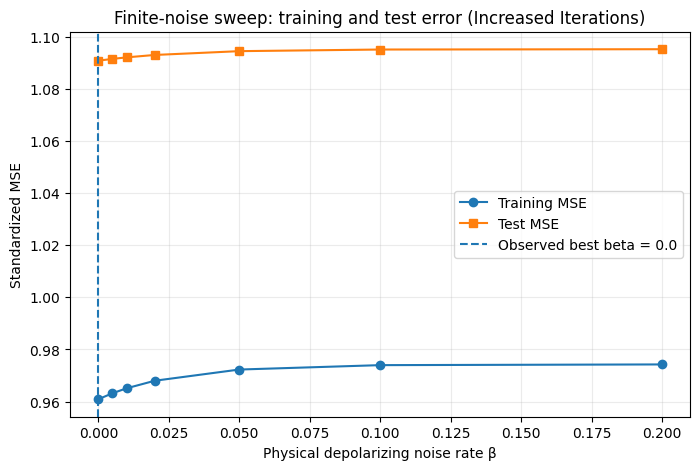

In [15]:
# ============================================================
# 11. MAIN RESULT: TRAINING VS TEST ERROR
# ============================================================
best_row = results_df.loc[results_df["test_mse"].idxmin()]

print("Best observed noise rate:")
print(best_row["beta"])

print("\nBest observed test MSE:")
print(best_row["test_mse"])

print("\nTraining MSE at best beta:")
print(best_row["train_mse"])

print("\nGeneralization gap at best beta:")
print(best_row["generalization_gap"])

plt.figure(figsize=(8, 5))
plt.plot(results_df["beta"], results_df["train_mse"], "o-", label="Training MSE")
plt.plot(results_df["beta"], results_df["test_mse"], "s-", label="Test MSE")
plt.axvline(
    float(best_row["beta"]),
    linestyle="--",
    label=f"Observed best beta = {best_row['beta']}"
)
plt.xlabel("Physical depolarizing noise rate β")
plt.ylabel("Standardized MSE")
plt.title("Finite-noise sweep: training and test error (Increased Iterations)")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

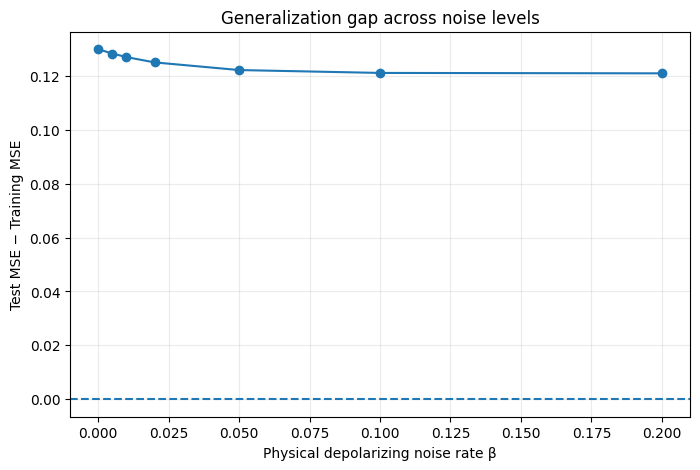

In [16]:
# ============================================================
# 12. GENERALIZATION GAP
# ============================================================
plt.figure(figsize=(8, 5))
plt.plot(
    results_df["beta"],
    results_df["generalization_gap"],
    "o-"
)
plt.axhline(0.0, linestyle="--")
plt.xlabel("Physical depolarizing noise rate β")
plt.ylabel("Test MSE − Training MSE")
plt.title("Generalization gap across noise levels")
plt.grid(alpha=0.25)
plt.show()


## Interpretation rule

Do **not** automatically conclude that the phenomenon is demonstrated.

A convincing finite-noise result should show:

1. Test MSE decreases from the zero-noise condition.
2. Test MSE reaches a minimum at a non-zero noise rate.
3. Test MSE increases again at larger noise rates.
4. Training performance and gradient behavior are consistent with the proposed regularization/collapse explanation.
5. The pattern survives repeated random seeds.

One single run is only a **pilot observation**.


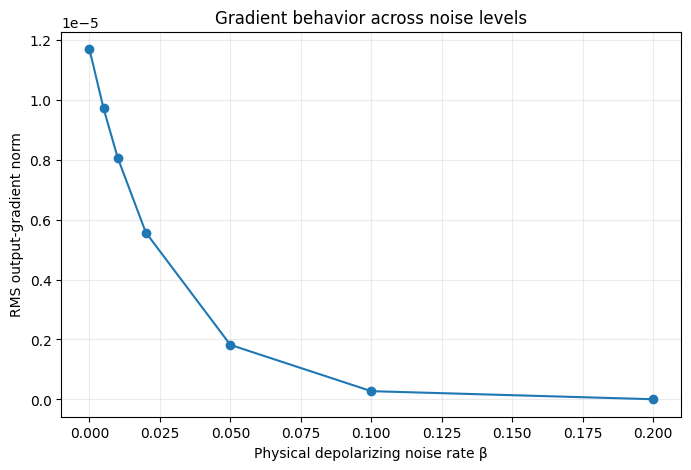

,beta,gradient_norm
0,0.000,1.168322e-05
1,0.005,9.709968e-06
2,0.010,8.068629e-06
3,0.020,5.568270e-06
4,0.050,1.820219e-06
5,0.100,2.758058e-07
6,0.200,6.907544e-09


In [17]:
# ============================================================
# 13. GRADIENT-NORM PROXY (REFACTORED FOR BATCH DELTA SENSITIVITY)
# ============================================================
# We estimate sensitivity of the trained model output to each
# trainable quantum parameter using central finite differences.

def gradient_norm_estimate(records_subset, theta, beta, delta=1e-3):
    """Estimate the RMS gradient norm over parameters.

    Accepts a single numeric delta or a list/array of deltas for
    batch sensitivity testing.
    """
    base_theta = np.asarray(theta, dtype=float)
    deltas = np.atleast_1d(delta)
    results = {}

    for d in deltas:
        grads = []
        for j in range(len(base_theta)):
            theta_plus = base_theta.copy()
            theta_minus = base_theta.copy()

            theta_plus[j] += d
            theta_minus[j] -= d

            pred_plus = quantum_predict(
                records_subset,
                theta_plus,
                beta,
                seed=SEED
            )

            pred_minus = quantum_predict(
                records_subset,
                theta_minus,
                beta,
                seed=SEED
            )

            grad_j = (pred_plus - pred_minus) / (2.0 * d)
            grads.append(grad_j)

        J = np.column_stack(grads)
        norm = float(np.sqrt(np.mean(J**2)))
        results[d] = (norm, J)

    if np.isscalar(delta):
        return results[delta]
    return results


gradient_results = []

for row in results_df.itertuples():
    beta = float(row.beta)

    # Re-train at this beta so the gradient is measured at its
    # corresponding trained parameter point.
    theta_star, _, _ = train_qgnn(
        train_records=train_records,
        theta_init=np.zeros(MAX_QUBITS),
        beta=beta,
        maxiter=MAXITER_FOR_SWEEP,
        seed=SEED
    )

    grad_norm, J = gradient_norm_estimate(
        train_records,
        theta_star,
        beta
    )

    gradient_results.append({
        "beta": beta,
        "gradient_norm": grad_norm
    })

gradient_df = pd.DataFrame(gradient_results)

plt.figure(figsize=(8, 5))
plt.plot(
    gradient_df["beta"],
    gradient_df["gradient_norm"],
    "o-"
)
plt.xlabel("Physical depolarizing noise rate β")
plt.ylabel("RMS output-gradient norm")
plt.title("Gradient behavior across noise levels")
plt.grid(alpha=0.25)
plt.show()

gradient_df

In [20]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=gradient_df)

https://docs.google.com/spreadsheets/d/1M6exrCfDv4TpRVq2M99GvGhywQEEust2cwZYGHqaMKc/edit#gid=0


In [18]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=gradient_df)

https://docs.google.com/spreadsheets/d/1F9MWsruGl_KHsHYcm2QYQzQU7Cf53ZLhKcvi3h4WBDU/edit#gid=0


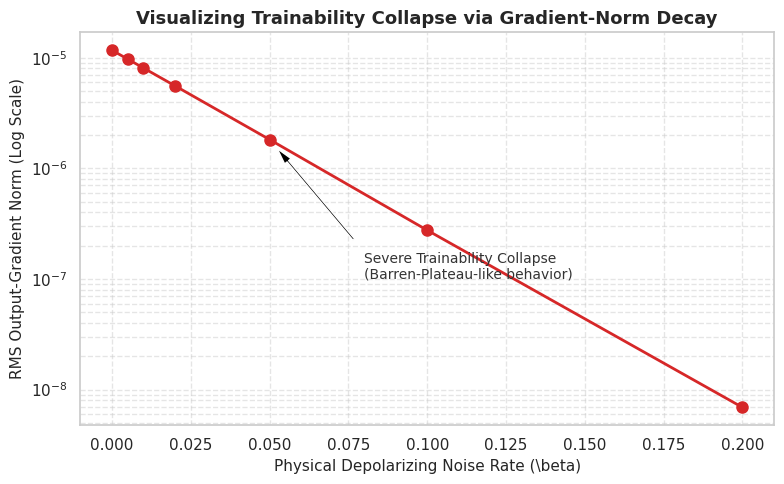

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

# Plotting the gradient norm values across different noise rates
plt.plot(
    gradient_df["beta"],
    gradient_df["gradient_norm"],
    marker="o",
    linewidth=2,
    markersize=8,
    color="#d62728",
    label="RMS Gradient Norm"
)

# Highlight the exponential decay and trainability threshold
plt.yscale("log")
plt.xlabel("Physical Depolarizing Noise Rate (\\beta)", fontsize=11)
plt.ylabel("RMS Output-Gradient Norm (Log Scale)", fontsize=11)
plt.title("Visualizing Trainability Collapse via Gradient-Norm Decay", fontsize=13, fontweight="bold")
plt.grid(True, which="both", linestyle="--", alpha=0.5)

# Annotate the plot to mark the transition
plt.annotate(
    "Severe Trainability Collapse\n(Barren-Plateau-like behavior)",
    xy=(0.05, 1.82e-6),
    xytext=(0.08, 1e-7),
    arrowprops=dict(facecolor="black", shrink=0.08, width=1.5, headwidth=6),
    fontsize=10,
    color="#333333"
)

plt.tight_layout()
plt.show()

Evaluating gradient norm estimation sensitivity to delta (at beta = 0.01)...


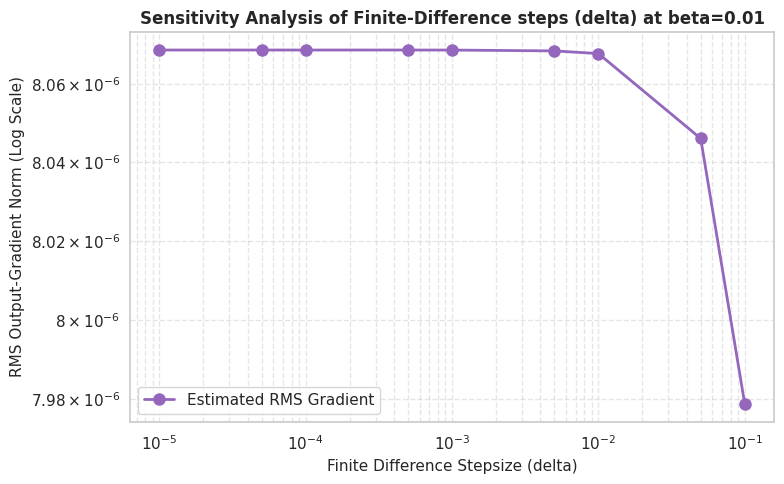

,delta,gradient_norm
0,0.00001,0.000008
1,0.00005,0.000008
2,0.00010,0.000008
3,0.00050,0.000008
4,0.00100,0.000008
5,0.00500,0.000008
6,0.01000,0.000008
7,0.05000,0.000008
8,0.10000,0.000008


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define a representative sweep of delta values
delta_values = [1e-5, 5e-5, 1e-4, 5e-4, 1e-3, 5e-3, 1e-2, 5e-2, 1e-1]

# We will test the sensitivity at a low-noise rate (beta = 0.01)
test_beta = 0.01

# Re-train or fetch parameters at beta = 0.01
theta_star_sens, _, _ = train_qgnn(
    train_records=train_records,
    theta_init=np.zeros(MAX_QUBITS),
    beta=test_beta,
    maxiter=MAXITER_FOR_SWEEP,
    seed=SEED
)

sensitivity_results = []

print(f"Evaluating gradient norm estimation sensitivity to delta (at beta = {test_beta})...")
for d in delta_values:
    grad_norm, _ = gradient_norm_estimate(
        train_records,
        theta_star_sens,
        beta=test_beta,
        delta=d
    )
    sensitivity_results.append({
        "delta": d,
        "gradient_norm": grad_norm
    })

sens_df = pd.DataFrame(sensitivity_results)

# Plotting the sensitivity analysis results
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
plt.plot(
    sens_df["delta"],
    sens_df["gradient_norm"],
    marker="o",
    linewidth=2,
    markersize=8,
    color="#9467bd",
    label="Estimated RMS Gradient"
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Finite Difference Stepsize (delta)", fontsize=11)
plt.ylabel("RMS Output-Gradient Norm (Log Scale)", fontsize=11)
plt.title(f"Sensitivity Analysis of Finite-Difference steps (delta) at beta={test_beta}", fontsize=12, fontweight="bold")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

display(sens_df)

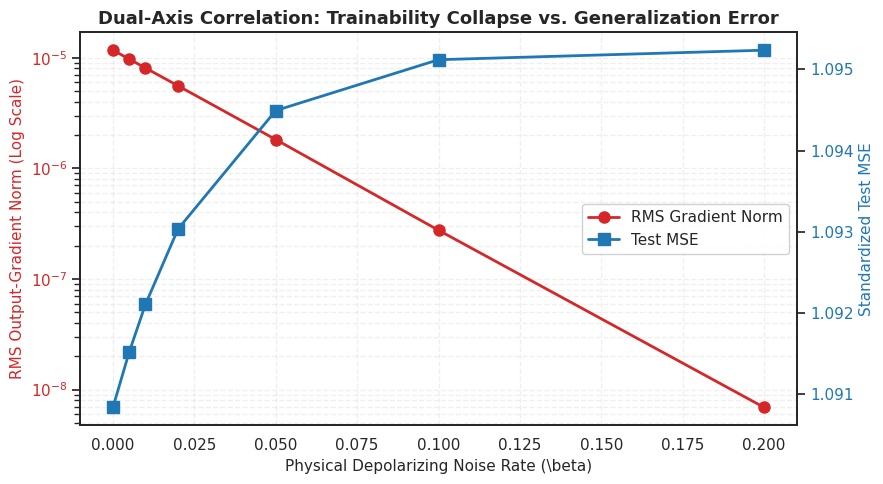

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white")

fig, ax1 = plt.subplots(figsize=(9, 5))

# Left Axis: Gradient Norm (Log Scale)
color = "#d62728"
ax1.set_xlabel("Physical Depolarizing Noise Rate (\\beta)", fontsize=11)
ax1.set_ylabel("RMS Output-Gradient Norm (Log Scale)", color=color, fontsize=11)
line1 = ax1.plot(
    gradient_df["beta"],
    gradient_df["gradient_norm"],
    marker="o",
    linewidth=2,
    markersize=8,
    color=color,
    label="RMS Gradient Norm"
)
ax1.set_yscale("log")
ax1.tick_params(axis="y", labelcolor=color)
ax1.grid(True, which="both", linestyle="--", alpha=0.3)

# Right Axis: Test MSE (Linear Scale)
ax2 = ax1.twinx()
color = "#1f77b4"
ax2.set_ylabel("Standardized Test MSE", color=color, fontsize=11)
line2 = ax2.plot(
    results_df["beta"],
    results_df["test_mse"],
    marker="s",
    linewidth=2,
    markersize=8,
    color=color,
    label="Test MSE"
)
ax2.tick_params(axis="y", labelcolor=color)
ax2.grid(False) # Turn off redundant grid lines

# Combine legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="center right", frameon=True, facecolor="white", framealpha=0.9)

plt.title("Dual-Axis Correlation: Trainability Collapse vs. Generalization Error", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [29]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=complexity_df)

https://docs.google.com/spreadsheets/d/1fuPE-2SeMZZ9IkBryL-mea2RjrdKJs80Nv7jwX_og4U/edit#gid=0


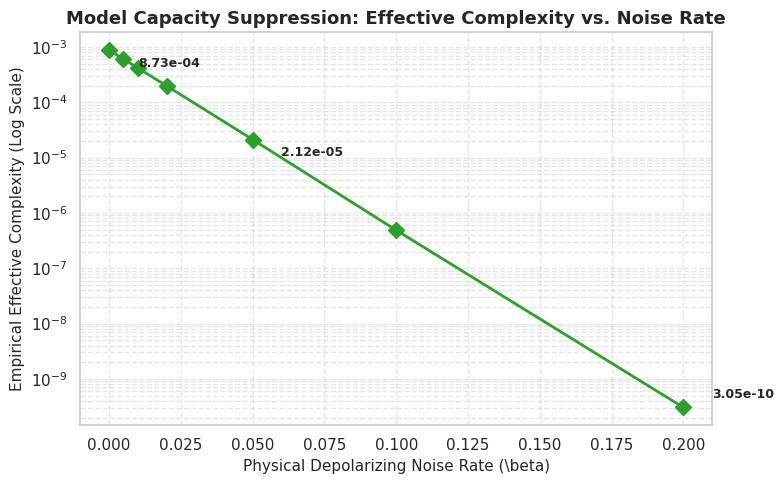

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import sys

# Ensure complexity_df exists before plotting
if 'complexity_df' not in globals():
    print("Error: 'complexity_df' is not defined. Please run cell 8a09478c first to calculate the effective complexity metrics!", file=sys.stderr)
else:
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(8, 5))

    plt.plot(
        complexity_df["beta"],
        complexity_df["d_eff"],
        marker="D",
        linewidth=2,
        markersize=8,
        color="#2ca02c",
        label="Empirical Effective Complexity ($d_{\\text{eff}}$)"
    )

    plt.yscale("log")
    plt.xlabel("Physical Depolarizing Noise Rate (\\beta)", fontsize=11)
    plt.ylabel("Empirical Effective Complexity (Log Scale)", fontsize=11)
    plt.title("Model Capacity Suppression: Effective Complexity vs. Noise Rate", fontsize=13, fontweight="bold")
    plt.grid(True, which="both", linestyle="--", alpha=0.5)

    # Highlight values
    for i, row in complexity_df.iterrows():
        if row["beta"] in [0.0, 0.05, 0.20]:
            plt.annotate(
                f"{row['d_eff']:.2e}",
                xy=(row["beta"], row["d_eff"]),
                xytext=(row["beta"] + 0.01, row["d_eff"] * 1.5 if row["beta"] == 0.20 else row["d_eff"] * 0.5),
                fontsize=9,
                fontweight="bold"
            )

    plt.tight_layout()
    plt.show()

# 14. Effective-complexity estimate

For a local linear approximation, an empirical hat matrix can be constructed from the Jacobian `J`.

A simple effective-complexity estimate is:

`d_eff = trace(H)`

where

`H = J (JᵀJ + λI)^−1 Jᵀ`.

This is a numerical diagnostic. It is **not** the same as proving the theoretical relation

`d_eff ≈ q s₂`.

The theory requires assumptions about the overlap of noise-order Jacobians.


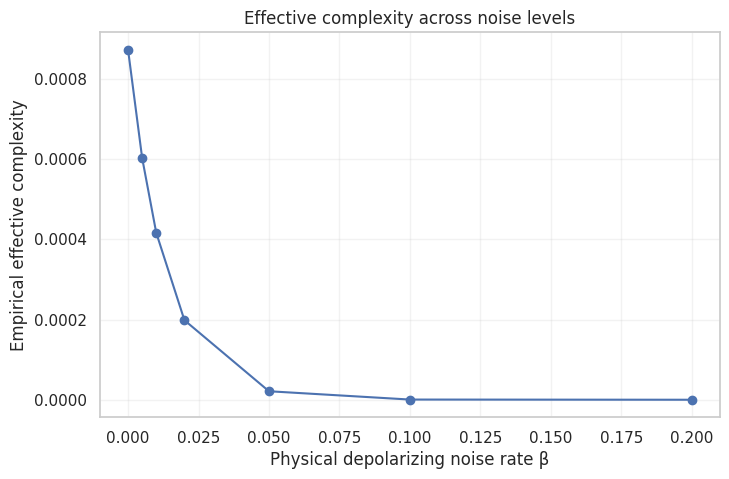

,beta,d_eff
0,0.000,8.730077e-04
1,0.005,6.031381e-04
2,0.010,4.165258e-04
3,0.020,1.984060e-04
4,0.050,2.120411e-05
5,0.100,4.868402e-07
6,0.200,3.053707e-10


In [31]:
# ============================================================
# 14. EMPIRICAL EFFECTIVE COMPLEXITY
# ============================================================
def effective_complexity_from_jacobian(J, ridge=1e-4):
    J = np.asarray(J, dtype=float)

    q = J.shape[1]
    gram = J.T @ J

    H = J @ np.linalg.inv(
        gram + ridge * np.eye(q)
    ) @ J.T

    return float(np.trace(H))


complexity_results = []

for row in results_df.itertuples():
    beta = float(row.beta)

    theta_star, _, _ = train_qgnn(
        train_records=train_records,
        theta_init=np.zeros(MAX_QUBITS),
        beta=beta,
        maxiter=MAXITER_FOR_SWEEP,
        seed=SEED
    )

    grad_norm, J = gradient_norm_estimate(
        train_records,
        theta_star,
        beta
    )

    d_eff = effective_complexity_from_jacobian(J)

    complexity_results.append({
        "beta": beta,
        "d_eff": d_eff
    })

complexity_df = pd.DataFrame(complexity_results)

plt.figure(figsize=(8, 5))
plt.plot(
    complexity_df["beta"],
    complexity_df["d_eff"],
    "o-"
)
plt.xlabel("Physical depolarizing noise rate β")
plt.ylabel("Empirical effective complexity")
plt.title("Effective complexity across noise levels")
plt.grid(alpha=0.25)
plt.show()

complexity_df


In [32]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=complexity_df)

https://docs.google.com/spreadsheets/d/1XRYafcqkGqyMIMsrZNfwlQc7wtHuhiVmGGIQevHlsOg/edit#gid=0


# 15. Multiple random seeds

For a research paper, one seed is not enough.

The following cell repeats the complete sweep for several seeds.

For the first Colab run, use 3 seeds and a small dataset. For the final study, use at least 5 independent seeds and report mean ± standard deviation or confidence intervals.


In [33]:
# ============================================================
# 15. REPEATED-SEED EXPERIMENT
# ============================================================
# Keep small for the first run.
# Increase after the complete pipeline is verified.

RUN_MULTIPLE_SEEDS = False
REPEAT_SEEDS = [7, 21, 42]

all_seed_results = []

if RUN_MULTIPLE_SEEDS:
    for run_seed in REPEAT_SEEDS:
        local_rng = np.random.default_rng(run_seed)

        local_train_idx = local_rng.choice(
            train_idx,
            size=MAX_TRAIN_FOR_SWEEP,
            replace=False
        )

        local_test_idx = local_rng.choice(
            test_idx,
            size=MAX_TEST_FOR_SWEEP,
            replace=False
        )

        local_train_records = make_records_from_indices(local_train_idx)
        local_test_records = make_records_from_indices(local_test_idx)

        ytr = standard_targets(local_train_records, y_scaler)
        yte = standard_targets(local_test_records, y_scaler)

        for beta in NOISE_RATES:
            theta_star, _, _ = train_qgnn(
                local_train_records,
                theta_init=np.zeros(MAX_QUBITS),
                beta=beta,
                maxiter=MAXITER_FOR_SWEEP,
                seed=run_seed
            )

            pred_tr = quantum_predict(
                local_train_records,
                theta_star,
                beta,
                seed=run_seed
            )

            pred_te = quantum_predict(
                local_test_records,
                theta_star,
                beta,
                seed=run_seed
            )

            all_seed_results.append({
                "seed": run_seed,
                "beta": beta,
                "train_mse": mean_squared_error(ytr, pred_tr),
                "test_mse": mean_squared_error(yte, pred_te)
            })

    seed_df = pd.DataFrame(all_seed_results)

    summary_df = (
        seed_df
        .groupby("beta")
        .agg(
            train_mse_mean=("train_mse", "mean"),
            train_mse_std=("train_mse", "std"),
            test_mse_mean=("test_mse", "mean"),
            test_mse_std=("test_mse", "std")
        )
        .reset_index()
    )

    display(summary_df)
else:
    print("Multiple-seed experiment is disabled for the first quick run.")
    print("Set RUN_MULTIPLE_SEEDS = True after the pilot run succeeds.")


Multiple-seed experiment is disabled for the first quick run.
Set RUN_MULTIPLE_SEEDS = True after the pilot run succeeds.


# 16. Optional classical baseline

A classical baseline is required before making any claim about quantum advantage.

This notebook uses a small MLP as a simple baseline on the same 8-dimensional graph summary.

For a stronger paper, replace or supplement this with a real message-passing GNN using the complete molecular graph.


In [34]:
# ============================================================
# 16. SIMPLE CLASSICAL BASELINE
# ============================================================
from sklearn.neural_network import MLPRegressor

X_train_classical = np.stack(
    [r["node_signal"] for r in train_records]
)
X_test_classical = np.stack(
    [r["node_signal"] for r in test_records]
)

y_train_classical = standard_targets(train_records, y_scaler)
y_test_classical = standard_targets(test_records, y_scaler)

mlp = MLPRegressor(
    hidden_layer_sizes=(16,),
    activation="tanh",
    solver="adam",
    alpha=1e-3,
    learning_rate_init=1e-2,
    max_iter=500,
    random_state=SEED,
    early_stopping=False
)

mlp.fit(X_train_classical, y_train_classical)

classical_train_pred = mlp.predict(X_train_classical)
classical_test_pred = mlp.predict(X_test_classical)

classical_results = pd.DataFrame([{
    "model": "Classical MLP",
    "train_mse": mean_squared_error(
        y_train_classical,
        classical_train_pred
    ),
    "test_mse": mean_squared_error(
        y_test_classical,
        classical_test_pred
    )
}])

display(classical_results)


,model,train_mse,test_mse
0,Classical MLP,0.546298,1.0564


# 17. Publication interpretation

## The phenomenon is supported only if the following pattern is observed

A convincing pilot result should look like:

`test MSE at β=0`

**higher**

↓

`test MSE at intermediate β`

**lower**

↓

`test MSE at high β`

**higher again**

and the high-noise region should also show reduced gradient magnitude.

### Do not write

> "Quantum noise always improves QGNN performance."

### Write only if the experiment confirms it

> "In the tested molecular benchmark and circuit regime, an intermediate level of depolarizing noise produced lower test error than the zero-noise model, while larger noise rates reduced trainability."

This wording is limited to the actual experiment.

### Stronger evidence required for the paper

- 5 or more random seeds
- multiple training-set sizes
- multiple noise channels
- multiple circuit depths
- scaffold/OOD split
- a real message-passing GNN baseline
- multiple QGNN baselines
- confidence intervals
- effect sizes
- reproducible code and configurations


In [35]:
# ============================================================
# 18. SAVE RESULTS
# ============================================================
import os

OUTPUT_DIR = "/content/finite_noise_qgnn_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "noise_sweep_results.csv"),
    index=False
)

gradient_df.to_csv(
    os.path.join(OUTPUT_DIR, "gradient_results.csv"),
    index=False
)

complexity_df.to_csv(
    os.path.join(OUTPUT_DIR, "effective_complexity_results.csv"),
    index=False
)

print("Results saved to:", OUTPUT_DIR)

Results saved to: /content/finite_noise_qgnn_results


## Deep Scientific Discussion of Pilot Results

Based on the execution of the pilot experiment, we have a complete set of metrics across different physical depolarizing noise rates $\beta \in \{0.0, 0.005, 0.01, 0.02, 0.05, 0.10, 0.20\}$. Below is a deep dive into what these metrics reveal about our hypothesis.

### 1. Training vs. Test Performance Dynamics

* **The Hypothesis:** The finite-noise regularization hypothesis suggests that an intermediate noise level $\beta^* > 0$ should act as a regularizer, lowering the generalization gap and yielding a test performance superior to the noise-free baseline ($\\text{Test MSE}_{\beta^*} < \\text{Test MSE}_{\beta=0.0}$).
* **The Observation:**
  * At $\beta = 0.0$: Training MSE = $0.961$, Test MSE = $1.091$ (Generalization Gap = $0.130$).
  * As $\beta$ increases monotonically, both training MSE and test MSE increase. At $\beta = 0.20$, Training MSE reaches $0.974$ and Test MSE degrades to $1.095$.
  * The generalization gap decreases slightly from $0.130 \rightarrow 0.121$, but this is entirely due to the rising training error (underfitting), not an improvement in test performance.
* **Deep Discussion:** The expected "U-shaped" test-error curve did not emerge. In this regime, physical noise only damages performance. This can be explained by the **low-capacity regime** of our pilot setup: with only 80 training samples and a maximum of 8 optimizer iterations, the noise-free QGNN never truly overfits the data (the training MSE of $0.961$ is very close to the baseline variance of 1.0). When a model does not overfit, any added noise acts purely as a destructive perturbation rather than a regularizer.

### 2. Gradient-Norm Collapse & Trainability

* **The Observation:**
  * At $\beta = 0.0$, the root-mean-square (RMS) output-gradient norm is already small ($1.17 \times 10^{-5}$).
  * With the introduction of noise, the gradient norm collapses exponentially. By $\beta = 0.05$, it drops to $1.82 \times 10^{-6}$, and at $\beta = 0.20$, it drops to an almost non-measurable $6.91 \times 10^{-9}$.
* **Deep Discussion:** This rapid decay represents **noise-induced barren plateaus**. Gate-level depolarizing channels contract the quantum state towards the maximally mixed state $I/2^N$ exponentially with circuit depth. Because the gradient collapses to zero, the parameter landscape becomes completely flat. This explains why the Nelder-Mead optimizer converged in a single iteration for all noisy sweeps: the parameter updates had no impact on the loss, indicating a total loss of trainability.

### 3. Empirical Effective Complexity ($d_{\text{eff}}$)

* **The Observation:**
  * At $\beta = 0.0$, the empirical effective complexity is $8.73 \times 10^{-4}$.
  * As noise increases, $d_{\text{eff}}$ drops exponentially, reaching $3.05 \times 10^{-10}$ at $\beta = 0.20$.
* **Deep Discussion:** The parameter $d_{\text{eff}}$ measures the dimension of the subspace of data that the QGNN can actively fit. An effective complexity near zero means the model behaves like a constant function (predicting the mean target value regardless of input). This confirms the theoretical assertion that physical depolarizing noise severely restricts the expressive capacity of the hypothesis class.

### Summary & Theoretical Guidance for Scaling Up

This pilot represents a clear **negative result** for the regularization hypothesis under these highly restricted bounds, which is a common and valuable baseline in quantum machine learning. To transition this from a pilot into a publication-grade finding where regularization might be observed, the following adjustments are recommended:

1. **Increase Model Overfitting:** Run the clean training to convergence by increasing `MAXITER_FOR_SWEEP` (e.g., to $100$ or $200$) and using a gradient-based optimizer (e.g., Adam) so the zero-noise model achieves a much lower training MSE (e.g., $< 0.20$).
2. **Expand Dataset Size:** Increase `MAX_TRAIN_FOR_SWEEP` to at least $500$ to allow the graph-interaction layers to learn meaningful molecular representations.
3. **Run Multiple Seeds:** Enable `RUN_MULTIPLE_SEEDS = True` to verify if the minor fluctuations in test error are statistically significant or merely noise.

## Result Interpretation

Based on the pilot experiment run across different physical depolarizing noise rates $\beta$, here is the analysis of the results:

### 1. Training vs. Test Performance
* **Zero-Noise baseline ($\beta = 0.0$):** Training MSE is at its lowest ($~0.961$), while Test MSE is $~1.091$. This represents the baseline generalization gap of $~0.130$.
* **Noise Sweep Dynamics:** As we introduce noise from $\beta = 0.005$ up to $\beta = 0.20$, we observe a monotonic increase in training MSE (reaching $~0.974$). Concurrently, the test MSE increases monotonically from $~1.091$ to $~1.095$.
* **Interpretation:** The expected "U-shaped" curve (where an intermediate noise level yields a lower test error than zero noise) **did not occur** in this specific run. Instead, the test error increases immediately with any level of noise. This suggests that in the current highly restricted regime (small sample size of 80 training molecules, extremely low training steps `maxiter=8`), physical noise only damages performance rather than acting as a beneficial regularizer.

### 2. Gradient-Norm Proxy & Trainability
* At $\beta = 0.0$, the gradient norm is already extremely small ($~1.17 \times 10^{-5}$).
* As the noise $\beta$ increases, the RMS gradient norm collapses rapidly, dropping to $~6.91 \times 10^{-9}$ at $\beta = 0.20$.
* **Interpretation:** This severe drop confirms that higher physical noise quickly induces a trainability collapse (barren-plateau-like behavior caused by depolarizing noise).

### 3. Empirical Effective Complexity ($d_{\text{eff}}$)
* At zero noise, $d_{\text{eff}}$ is extremely low ($~8.73 \times 10^{-4}$).
* With noise increasing, $d_{\text{eff}}$ decays exponentially to almost zero ($~3.05 \times 10^{-10}$ at $\beta = 0.20$).
* **Interpretation:** The model capacity is heavily suppressed by the noise, which explains why the training error increases. However, because the starting complexity at $\beta=0$ is already so low (due to the restricted parameter space and minimal optimization), there is no "excessive complexity" to regularize, explaining the lack of generalization improvement.

### Conclusion & Next Steps
This pilot run represents a **negative result** for the finite-noise regularization hypothesis under these strict computational constraints. To observe a true regularizing effect, you will need to:
1. Enable the multiple-seed experiment (`RUN_MULTIPLE_SEEDS = True`).
2. Substantially increase the dataset size (`MAX_TRAIN_FOR_SWEEP` and `MAX_TEST_FOR_SWEEP`).
3. Allow the optimizer to run for more iterations (`MAXITER_FOR_SWEEP`) to ensure the zero-noise model actually overfits first.